Plotting the processed data to visualize the steps.

Author: Tayler LaSharr

Date: September 2024

Read in libraries and the data we care about.

In [49]:
import rasterio
from rasterio.enums import Resampling
from rasterio.mask import mask
import numpy as np
import matplotlib.pyplot as plt
import os
import re
from datetime import datetime
import geopandas as gpd

## define the directories for AZ and WY
base_dir = r'H:\My Drive\DroughtSurfing'
locations = ['AZ', 'WY', 'UT']
# locations = ['WY', 'UT']

## define file paths for the exported GeoTIFFs within each directory
ndvi_file_patterns = {
    'modis_ndvi': 'modis_ndvi.tif',  # single file
    'modis_ndvi_filtered': 'modis_ndvi_filtered.tif',  # single file
    'modis_ndvi_corrected': 'modis_ndvi_corrected_{}.tif',  # yearly files
    'smoothed_ndvi': 'smoothed_ndvi_{}.tif'  # yearly files
}
## get the years
years = range(2015, 2023 + 1)  # Modify this range based on your data

Functions for plotting.

In [50]:
def extract_dates(band_names):
    dates = []
    for name in band_names:
        # Extract the date part from the name using regex
        match = re.search(r'(\d{4}_\d{2}_\d{2})', name)
        if match:
            date_str = match.group(1)
            # Convert string to datetime object
            date_obj = datetime.strptime(date_str, '%Y_%m_%d')
            dates.append(date_obj)
    return dates

# Function to read the bounding box for each location
def read_bounding_box(location, base_dir, bounding_box_filename):
    # Construct the path to the bounding box shapefile for the current location
    bounding_box_path = os.path.join(base_dir, location, bounding_box_filename)
    # Read the shapefile using GeoPandas
    study_area = gpd.read_file(bounding_box_path)
    return study_area

# Function to reproject the bounding box to match the raster CRS (if necessary)
def reproject_bounding_box(study_area, raster_crs):
    # Check if the shapefile is already in the same CRS as the raster
    if study_area.crs != raster_crs:
        # Reproject the bounding box to match the raster CRS
        study_area_reprojected = study_area.to_crs(raster_crs)
        print(f"Reprojected CRS: {study_area_reprojected.crs}")
    else:
        study_area_reprojected = study_area
    
    # Convert the geometry to a format that rasterio.mask can handle
    study_area_geom = [study_area_reprojected.geometry.union_all().__geo_interface__]
    return study_area_geom

def read_and_stack_ndvi_data(tiff_dir, file_pattern, years, study_area_geom, target_shape=None):
    stacked_ndvi = []
    dates = []

    for year in years:
        file_name = file_pattern.format(year)
        ndvi_path = os.path.join(tiff_dir, file_name)

        if os.path.exists(ndvi_path):
            with rasterio.open(ndvi_path) as src:
                # Get the CRS of the raster and reproject the bounding box to match it
                raster_crs = src.crs
                study_area_geom_reprojected = reproject_bounding_box(study_area_geom, raster_crs)

                # Clip the raster to the study area using rasterio.mask.mask
                ndvi_data, clipped_transform = mask(src, study_area_geom_reprojected, crop=True)

                # Resample to match the target shape, if necessary
                if target_shape is not None and (src.height != target_shape[0] or src.width != target_shape[1]):
                    print(f"Resampling {file_name} from {src.shape} to {target_shape}")
                    ndvi_data = resample_raster(src, target_shape)
                else:
                    if target_shape is None:
                        target_shape = (src.height, src.width)

                stacked_ndvi.append(ndvi_data)

                # Get band descriptions (dates)
                band_names = src.descriptions
                dates.extend(extract_dates(band_names))

    # Stack all the NDVI arrays along the first dimension (time)
    if stacked_ndvi:
        stacked_ndvi = np.concatenate(stacked_ndvi, axis=0)

    return dates, stacked_ndvi, target_shape

# Function to resample a raster to a target shape
def resample_raster(src, target_shape):
    """Resample the raster to match the target shape."""
    data = src.read(
        out_shape=(src.count, target_shape[0], target_shape[1]),
        resampling=Resampling.bilinear  # or Resampling.nearest
    )
    return data

# Function to calculate mean NDVI over time for each stack
def calculate_mean_ndvi(ndvi_stack):
    # If ndvi_stack is a list of arrays, stack them along a new axis
    if isinstance(ndvi_stack, list):
        ndvi_stack = np.stack(ndvi_stack)

    # Calculate the mean NDVI across time steps
    return [np.nanmean(ndvi_stack[i, :, :]) for i in range(ndvi_stack.shape[0])]

def calculate_median_ndvi(ndvi_stack):
    # If ndvi_stack is a list of arrays, stack them along a new axis
    if isinstance(ndvi_stack, list):
        ndvi_stack = np.stack(ndvi_stack)

    # Calculate the mean NDVI across time steps
    return [np.nanmedian(ndvi_stack[i, :, :]) for i in range(ndvi_stack.shape[0])]


# Function to read NDVI data and clip it to the study area, returning the dates and clipped data
def read_single_ndvi_file(ndvi_path, study_area_geom):
    with rasterio.open(ndvi_path) as src:
        raster_crs = src.crs
        study_area_geom_reprojected = reproject_bounding_box(study_area_geom, raster_crs)
        
        try:
            # Clip the raster to the study area using rasterio.mask.mask
            clipped_ndvi_data, clipped_transform = mask(src, study_area_geom_reprojected, crop=True)
        except ValueError as e:
            print(f"Error clipping raster: {e}")
            return [], []  # Return empty lists if clipping fails
        
        band_names = src.descriptions  # Get band descriptions (dates)
        dates = extract_dates(band_names)
    
    return dates, clipped_ndvi_data



Plot the figures (unscaled data).

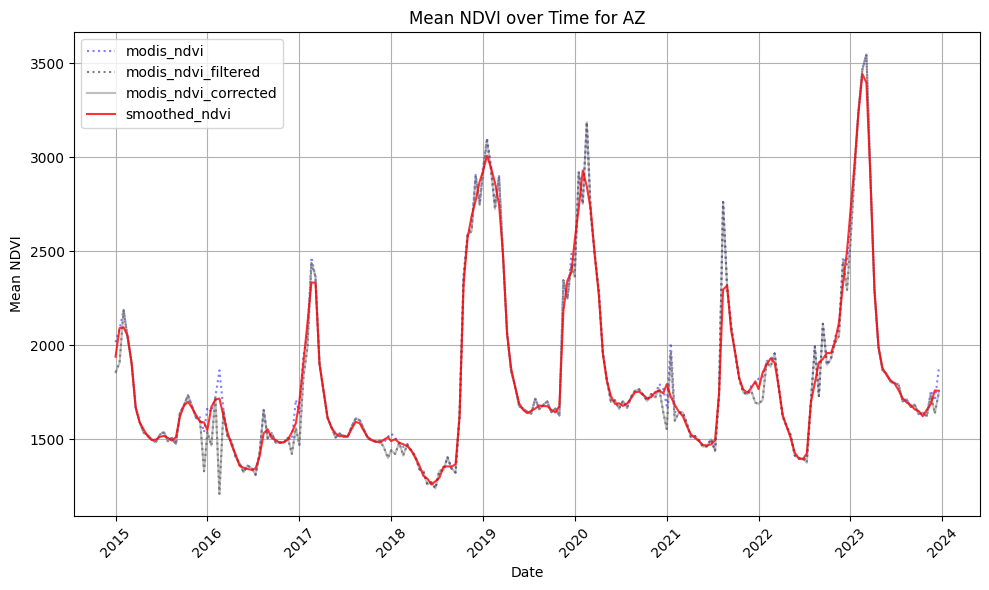

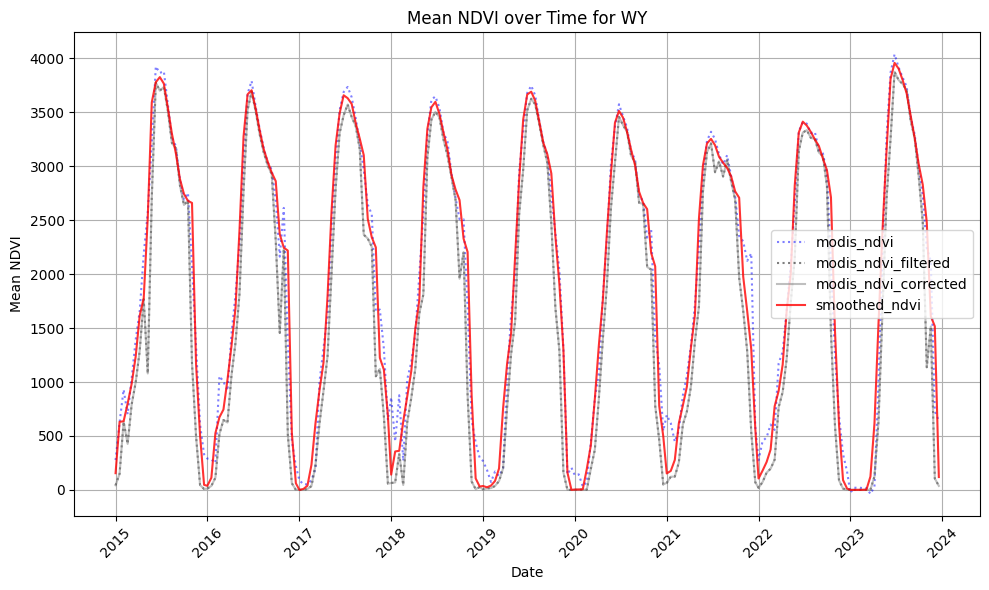

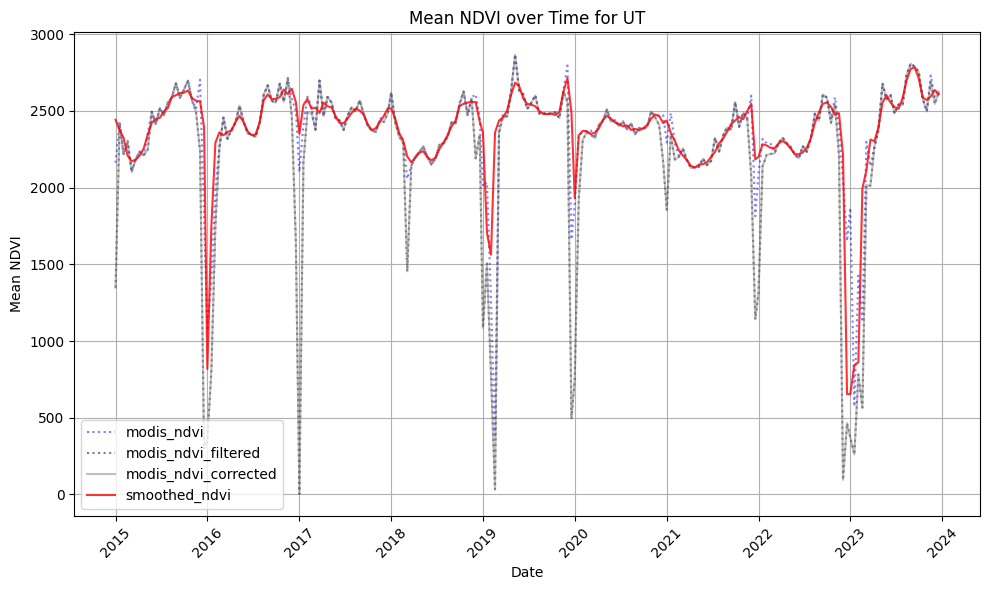

In [51]:
# Function to plot NDVI over time, cropping to the bounding box of each location
def plot_ndvi_over_time(locations, file_patterns, years, base_dir, bounding_box_filename):
    for location in locations:
        plt.figure(figsize=(10, 6))
        tiff_dir = os.path.join(base_dir, location)

        # Read the corresponding bounding box for the current location
        study_area = read_bounding_box(location, base_dir, bounding_box_filename)

        # Define colors and line styles for different NDVI products
        styles = [':', ':', '-', '-']
        colors = ['blue', 'black', 'gray', 'red']
        alphas = [0.5, 0.5, 0.5, .8]

        target_shape = None  # To store the target shape for resampling

        for i, (label, file_pattern) in enumerate(file_patterns.items()):
            if 'corrected' in label or 'smoothed' in label:
                # For 'modis_ndvi_corrected' and 'smoothed_ndvi', stack yearly files
                dates, stacked_ndvi, target_shape = read_and_stack_ndvi_data(tiff_dir, file_pattern, years, study_area, target_shape)
            else:
                # For 'modis_ndvi' and 'modis_ndvi_filtered', read a single .tif file and clip to study area
                ndvi_path = os.path.join(tiff_dir, file_pattern)
                dates, stacked_ndvi = read_single_ndvi_file(ndvi_path, study_area)

            # Check if stacked_ndvi is valid (i.e., not empty)
            if isinstance(stacked_ndvi, list) and len(stacked_ndvi) == 0:
                print(f"No valid NDVI data for {label} in {location}. Skipping...")
                continue

            # Ensure stacked_ndvi is a NumPy array
            stacked_ndvi = np.array(stacked_ndvi)

            # Calculate mean NDVI for each time step
            mean_ndvi = calculate_mean_ndvi(stacked_ndvi)

            # Plot NDVI for each product
            plt.plot(dates, mean_ndvi, label=label, linestyle=styles[i], color=colors[i], alpha=alphas[i])

        # Add labels, title, and grid for each location
        plt.title(f'Mean NDVI over Time for {location}')
        plt.xlabel('Date')
        plt.ylabel('Mean NDVI')
        plt.legend(loc='best')
        plt.grid(True)
        plt.xticks(rotation=45)
        plt.tight_layout()

        # Show each plot separately
        plt.show()

# Call the function to plot the NDVI over time for each location
plot_ndvi_over_time(locations, ndvi_file_patterns, years, base_dir, bounding_box_filename) 


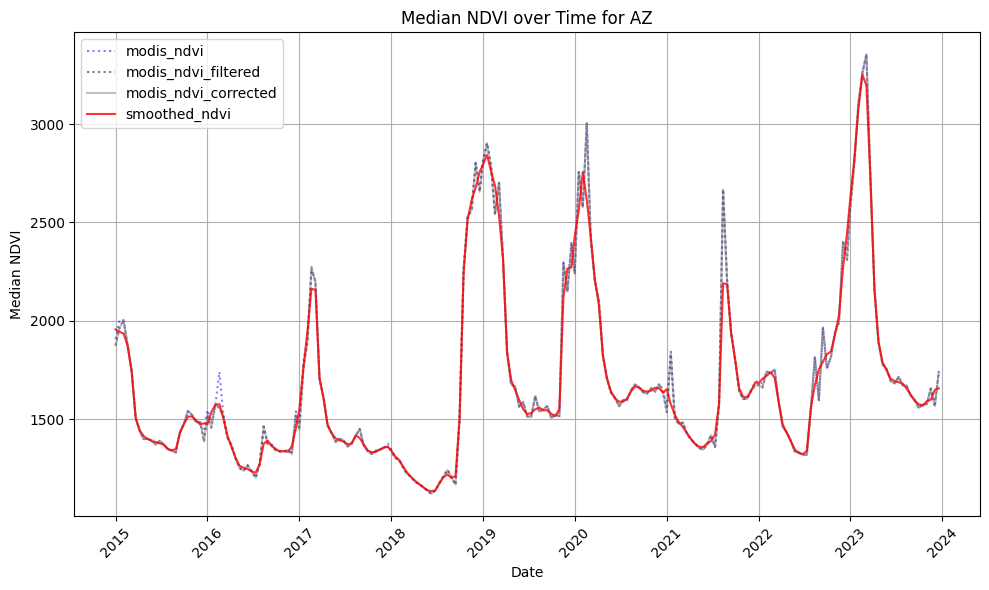

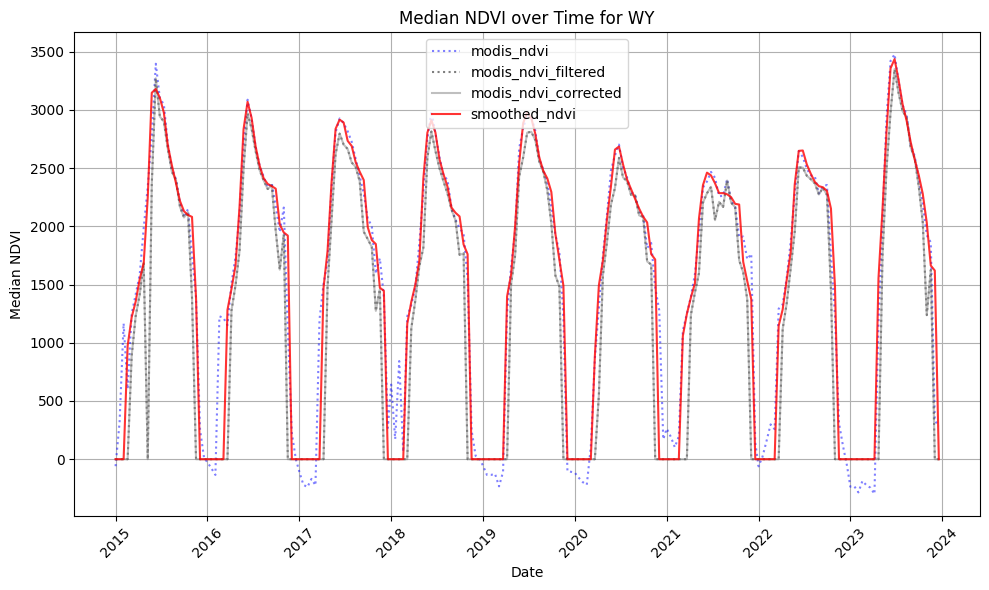

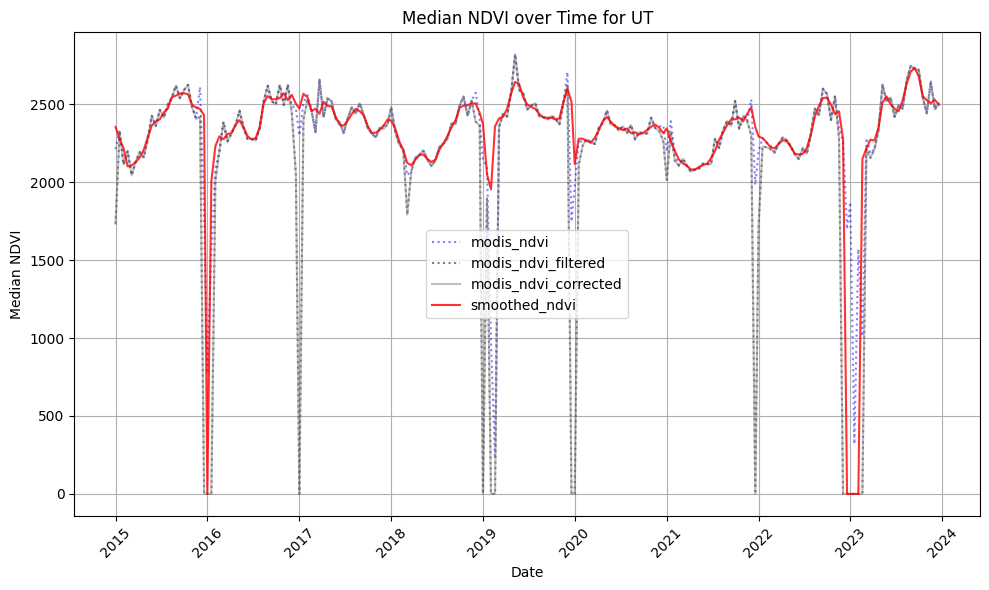

In [52]:
# Function to plot NDVI over time, cropping to the bounding box of each location
def plot_ndvi_over_time(locations, file_patterns, years, base_dir, bounding_box_filename):
    for location in locations:
        plt.figure(figsize=(10, 6))
        tiff_dir = os.path.join(base_dir, location)

        # Read the corresponding bounding box for the current location
        study_area = read_bounding_box(location, base_dir, bounding_box_filename)

        # Define colors and line styles for different NDVI products
        styles = [':', ':', '-', '-']
        colors = ['blue', 'black', 'gray', 'red']
        alphas = [0.5, 0.5, 0.5, .8]

        target_shape = None  # To store the target shape for resampling

        for i, (label, file_pattern) in enumerate(file_patterns.items()):
            if 'corrected' in label or 'smoothed' in label:
                # For 'modis_ndvi_corrected' and 'smoothed_ndvi', stack yearly files
                dates, stacked_ndvi, target_shape = read_and_stack_ndvi_data(tiff_dir, file_pattern, years, study_area, target_shape)
            else:
                # For 'modis_ndvi' and 'modis_ndvi_filtered', read a single .tif file and clip to study area
                ndvi_path = os.path.join(tiff_dir, file_pattern)
                dates, stacked_ndvi = read_single_ndvi_file(ndvi_path, study_area)

            # Check if stacked_ndvi is valid (i.e., not empty)
            if isinstance(stacked_ndvi, list) and len(stacked_ndvi) == 0:
                print(f"No valid NDVI data for {label} in {location}. Skipping...")
                continue

            # Ensure stacked_ndvi is a NumPy array
            stacked_ndvi = np.array(stacked_ndvi)

            # Calculate mean NDVI for each time step
            median_ndvi = calculate_median_ndvi(stacked_ndvi)

            # Plot NDVI for each product
            plt.plot(dates, median_ndvi, label=label, linestyle=styles[i], color=colors[i], alpha=alphas[i])

        # Add labels, title, and grid for each location
        plt.title(f'Median NDVI over Time for {location}')
        plt.xlabel('Date')
        plt.ylabel('Median NDVI')
        plt.legend(loc='best')
        plt.grid(True)
        plt.xticks(rotation=45)
        plt.tight_layout()

        # Show each plot separately
        plt.show()

# Call the function to plot the NDVI over time for each location
plot_ndvi_over_time(locations, ndvi_file_patterns, years, base_dir, bounding_box_filename) 